Credit card Fraud Detection

STEP 1: Libraries imported successfully
STEP 2: Dataset loaded successfully
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431 

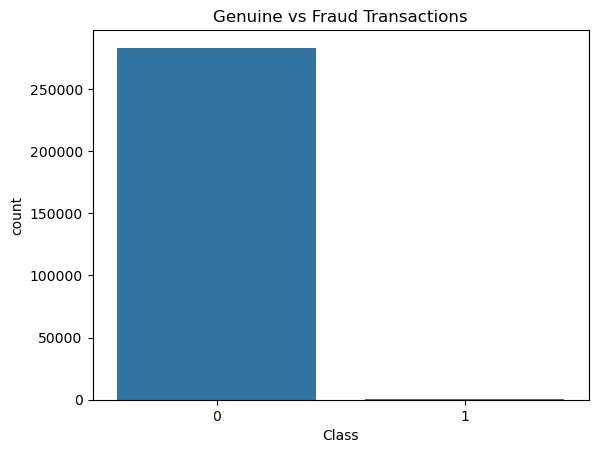

STEP 5: EDA completed

STEP 6: X and y separated
X shape: (283726, 30)
y shape: (283726,)

STEP 7: Train-test split completed
Training data: (226980, 30)
Testing data: (56746, 30)

Starting Logistic Regression training...
Logistic Regression trained successfully!
lr prediction: [0 0 0 ... 0 0 0]
lr prediction: [0.02162645 0.02007152 0.01024023 ... 0.04118568 0.04603167 0.02689938]
Logistic Regression prediction completed!

Starting Random Forest training...
Random Forest trained successfully!
random forest prediction: [0 0 0 ... 0 0 0]
random forest probability: [0. 0. 0. ... 0. 0. 0.]
Random Forest prediction completed!

Evaluating Logistic Regression...

Logistic Regression
Accuracy: 0.9753110351390406
Precision: 0.05638586956521739
Recall: 0.8736842105263158
F1 Score: 0.10593490746649649
PR-AUC: 0.6719244530518994

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87     

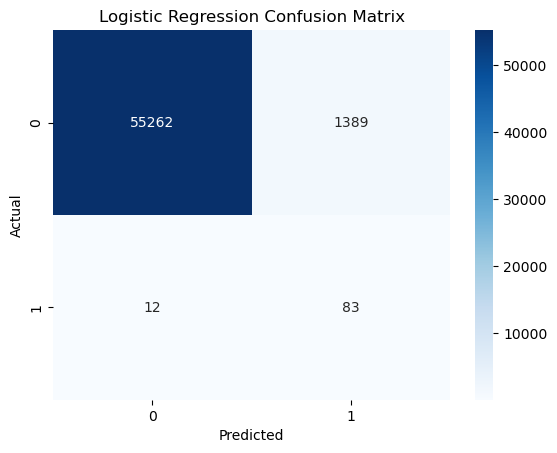


Evaluating Random Forest...

Random Forest
Accuracy: 0.9994713283755683
Precision: 0.9710144927536232
Recall: 0.7052631578947368
F1 Score: 0.8170731707317073
PR-AUC: 0.7977673337490048

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.97      0.71      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.85      0.91     56746
weighted avg       1.00      1.00      1.00     56746



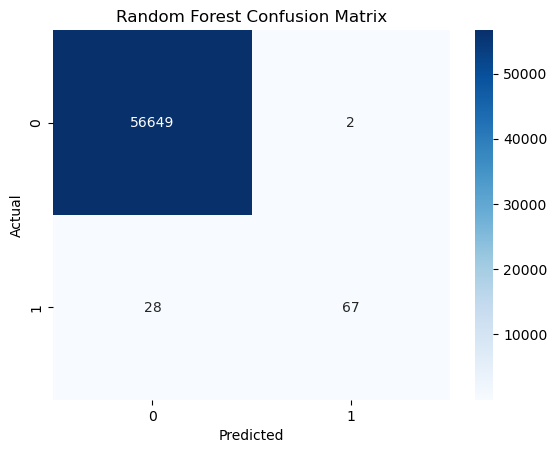


MODEL COMPARISON
                 Model  Accuracy  Precision    Recall  F1 Score    PR-AUC
0  Logistic Regression  0.975311   0.056386  0.873684  0.105935  0.671924
1        Random Forest  0.999471   0.971014  0.705263  0.817073  0.797767

NEW TRANSACTION PREDICTION
Genuine Transaction

PROJECT EXECUTED SUCCESSFULLY!


In [4]:

# ==========================================
# CREDIT CARD FRAUD DETECTION
# Logistic Regression + Random Forest
# ==========================================

# STEP 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    average_precision_score
)

print("STEP 1: Libraries imported successfully")


# STEP 2: Load dataset

df = pd.read_csv("creditcard.csv")

print("STEP 2: Dataset loaded successfully")
print(df.head())

print("Dataset shape:", df.shape)


# STEP 3: Understand dataset

print("\nDataset Information:")
print(df.info())

print("\nDataset Description:")
print(df.describe())


# STEP 4: Check missing values and duplicates

print("\nMissing values:", df.isnull().sum().sum())

print("Duplicate records:", df.duplicated().sum())

# Remove duplicate records
df.drop_duplicates(inplace=True)

print("Duplicates removed")
print("New dataset shape:", df.shape)


# STEP 5: Check fraud and genuine transactions

print("\nTransaction counts:")
print(df["Class"].value_counts())

sns.countplot(x="Class", data=df)
plt.title("Genuine vs Fraud Transactions")
plt.show()

print("STEP 5: EDA completed")


# STEP 6: Separate input and output

X = df.drop("Class", axis=1)

y = df["Class"]

print("\nSTEP 6: X and y separated")
print("X shape:", X.shape)
print("y shape:", y.shape)


# STEP 7: Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nSTEP 7: Train-test split completed")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# STEP 8: Logistic Regression model

print("\nStarting Logistic Regression training...")

lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

lr_pred = lr_model.predict(X_test)
print("lr prediction:",lr_pred)

lr_prob = lr_model.predict_proba(X_test)[:, 1]
print("lr prediction:",lr_prob)

print("Logistic Regression prediction completed!")


# STEP 9: Random Forest model

print("\nStarting Random Forest training...")

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

rf_pred = rf_model.predict(X_test)
print("random forest prediction:",rf_pred)

rf_prob = rf_model.predict_proba(X_test)[:, 1]
print("random forest probability:",rf_prob)

print("Random Forest prediction completed!")


# STEP 10: Evaluation function

def evaluate_model(name, y_test, y_pred, y_prob):

    print("\n==============================")
    print(name)
    print("==============================")

    print("Accuracy:",
          accuracy_score(y_test, y_pred))

    print("Precision:",
          precision_score(y_test, y_pred,
                          zero_division=0))

    print("Recall:",
          recall_score(y_test, y_pred,
                       zero_division=0))

    print("F1 Score:",
          f1_score(y_test, y_pred,
                   zero_division=0))

    print("PR-AUC:",
          average_precision_score(y_test, y_prob))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


# STEP 11: Evaluate Logistic Regression

print("\nEvaluating Logistic Regression...")

evaluate_model(
    "Logistic Regression",
    y_test,
    lr_pred,
    lr_prob
)


# STEP 12: Evaluate Random Forest

print("\nEvaluating Random Forest...")

evaluate_model(
    "Random Forest",
    y_test,
    rf_pred,
    rf_prob
)


# STEP 13: Compare both models

print("\nMODEL COMPARISON")

results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred)
    ],

    "Precision": [
        precision_score(y_test, lr_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],

    "F1 Score": [
        f1_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],

    "PR-AUC": [
        average_precision_score(y_test, lr_prob),
        average_precision_score(y_test, rf_prob)
    ]

})

print(results)


# STEP 14: Predict a transaction

print("\nNEW TRANSACTION PREDICTION")

new_transaction = X_test.iloc[[0]]

prediction = rf_model.predict(new_transaction)

if prediction[0] == 1:

    print("Fraudulent Transaction")

else:

    print("Genuine Transaction")

print("\nPROJECT EXECUTED SUCCESSFULLY!")
